# RA3 — Análise, Visualização e Aprendizado de Máquina

## 1. Introdução

Este projeto investiga fatores demográficos, clínicos e relacionados à hospitalização que podem estar associados às readmissões hospitalares em até 30 dias após a alta de pacientes com diabetes.

Utilizando a base de dados preparada durante o RA1, esta etapa contempla análises estatísticas descritivas, visualizações e a implementação de um modelo de aprendizado de máquina supervisionado.

O objetivo é identificar padrões nos atendimentos hospitalares históricos e avaliar se as características dos pacientes e das internações podem contribuir para a previsão de readmissões precoces.

### Pergunta central

Quais fatores demográficos, clínicos e relacionados à hospitalização estão associados às readmissões hospitalares em até 30 dias após a alta de pacientes com diabetes?

### Objetivos

- Descrever as principais características e distribuições da base de dados.
- Investigar associações entre características dos pacientes, fatores de hospitalização, informações sobre medicamentos e readmissões precoces.
- Desenvolver visualizações para identificar padrões e diferenças relevantes.
- Aplicar um algoritmo de classificação supervisionada para prever readmissões em até 30 dias.
- Avaliar o desempenho do modelo e discutir as limitações dos resultados.

## 2. Perguntas analíticas

A análise será orientada pelas seguintes perguntas específicas:

1. **Tempo de internação:** Como a duração da internação (`time_in_hospital`) se relaciona com as taxas de readmissão em até 30 dias?

2. **Utilização anterior dos serviços de saúde:** Em que medida as internações, emergências e consultas ambulatoriais anteriores (`number_inpatient`, `number_emergency` e `number_outpatient`) indicam maior probabilidade de readmissão precoce?

3. **Alterações na medicação:** As alterações nos tratamentos e as informações sobre medicamentos para diabetes (`change`, `diabetesMed` e `insulin`) estão associadas às readmissões precoces?

4. **Diferenças demográficas e diagnósticas:** Existem diferenças nos padrões de readmissão precoce entre as faixas etárias (`age`) e as categorias dos diagnósticos principais (`diag_1`)?

In [2]:
# Importação das bibliotecas e carregamento dos dados

from pathlib import Path

import pandas as pd
import numpy as np

# Localizar o arquivo preparado no RA1
caminhos = [
    Path("data/processed/diabetic_data_clean.csv"),
    Path("../data/processed/diabetic_data_clean.csv")
]

caminho_dados = next(
    (caminho for caminho in caminhos if caminho.exists()),
    None
)

# Carregar a base preparada
df = pd.read_csv(caminho_dados)

print("Base carregada com sucesso!")
print("Dimensões da base:", df.shape)

Base carregada com sucesso!
Dimensões da base: (101766, 48)


In [3]:
# Verificação de valores ausentes

valores_ausentes = df.isnull().sum()

resumo_ausentes = pd.DataFrame({
    "Valores ausentes": valores_ausentes,
    "Percentual (%)": (valores_ausentes / len(df)) * 100
})

resumo_ausentes = resumo_ausentes[
    resumo_ausentes["Valores ausentes"] > 0
].sort_values(by="Percentual (%)", ascending=False)

display(resumo_ausentes)

,Valores ausentes,Percentual (%)
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636


In [4]:
# Distribuição da variável-alvo

distribuicao_target = df["readmitido_30_dias"].value_counts().sort_index()

resumo_target = pd.DataFrame({
    "Classificação": [
        "Sem readmissão em até 30 dias",
        "Readmissão em até 30 dias"
    ],
    "Quantidade": [
        distribuicao_target.get(0, 0),
        distribuicao_target.get(1, 0)
    ]
})

resumo_target["Percentual (%)"] = (
    resumo_target["Quantidade"] / len(df) * 100
)

display(resumo_target)

,Classificação,Quantidade,Percentual (%)
0,Sem readmissão em até 30 dias,90409,88.840084
1,Readmissão em até 30 dias,11357,11.159916


### Considerações iniciais sobre a base de dados

A base utilizada nesta etapa corresponde ao conjunto de dados preparado durante o RA1, contendo 101.766 registros de atendimentos hospitalares e 48 variáveis.

A verificação dos valores ausentes identificou maior concentração nas variáveis `max_glu_serum` e `A1Cresult`, enquanto as demais variáveis apresentam proporções menores de dados ausentes.

A distribuição da variável-alvo demonstra um desequilíbrio entre as classes: 88,84% dos atendimentos não apresentaram readmissão em até 30 dias, enquanto 11,16% apresentaram readmissão nesse período.

Esse desequilíbrio será considerado na construção e avaliação do modelo de classificação, uma vez que a acurácia isoladamente pode não representar adequadamente sua capacidade de identificar os casos de readmissão precoce.

## 3. Análise estatística descritiva

Nesta seção, serão utilizadas medidas estatísticas descritivas para compreender as características e a distribuição dos dados relacionados às internações hospitalares e ao histórico de utilização dos serviços de saúde.

Serão analisadas medidas de tendência central, como média e mediana, e medidas de dispersão, como desvio-padrão, valores mínimos e máximos e quartis.

A análise também considerará a frequência das categorias das variáveis qualitativas, permitindo identificar características predominantes na população estudada.

As variáveis foram selecionadas de acordo com sua relação com as perguntas analíticas definidas para o projeto.

In [5]:
# Estatísticas descritivas das variáveis numéricas

variaveis_numericas = [
    "time_in_hospital",
    "number_inpatient",
    "number_emergency",
    "number_outpatient",
    "number_diagnoses"
]


#metodo describe calcula automaticamente as estatísticas descritivas das variáveis numéricas
estatisticas_numericas = df[variaveis_numericas].describe().T

estatisticas_numericas = estatisticas_numericas.rename(columns={
    "count": "Quantidade",
    "mean": "Média",
    "std": "Desvio padrão",
    "min": "Mínimo",
    "25%": "1º quartil", #valor abaixo do qual 25% dos dados estão localizados
    "50%": "Mediana",
    "75%": "3º quartil", #valor abaixo do qual 75% dos dados estão localizados
    "max": "Máximo"
})

display(estatisticas_numericas.round(2))

,Quantidade,Média,Desvio padrão,Mínimo,1º quartil,Mediana,3º quartil,Máximo
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_diagnoses,101766.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0


In [6]:
# Comparação das variáveis numéricas por ocorrência de readmissão
#std = desvio padrão

comparacao_readmissao = (
    df.groupby("readmitido_30_dias")[variaveis_numericas]
    .agg(["mean", "median", "std"])
)

comparacao_readmissao.index = [
    "Sem readmissão em até 30 dias",
    "Readmissão em até 30 dias"
]

display(comparacao_readmissao.round(2))

time_in_hospital              number_inpatient  \
                                          mean median   std             mean   
Sem readmissão em até 30 dias             4.35    4.0  2.98             0.56   
Readmissão em até 30 dias                 4.77    4.0  3.03             1.22   

                                           number_emergency               \
                              median   std             mean median   std   
Sem readmissão em até 30 dias    0.0  1.13             0.18    0.0  0.86   
Readmissão em até 30 dias        0.0  1.95             0.36    0.0  1.37   

                              number_outpatient              number_diagnoses  \
                                           mean median   std             mean   
Sem readmissão em até 30 dias              0.36    0.0  1.26             7.39   
Readmissão em até 30 dias                  0.44    0.0  1.30             7.69   

                                            
                              median   std  
Sem readmissão em até 30 dias    8.0  1.95  
Readmissão em até 30 dias        9.0  1.77

### Análise das variáveis categóricas

Além das variáveis numéricas, serão analisadas características categóricas dos pacientes e dos tratamentos, incluindo faixa etária, gênero, alterações na medicação e utilização de insulina.

Para essas variáveis, serão utilizadas tabelas de frequência absoluta e relativa, permitindo identificar as categorias mais recorrentes na base de dados.

In [7]:
# 12. Distribuição dos atendimentos por faixa etária

distribuicao_idade = (
    df["age"]
    .value_counts()
    .reindex([
        "[0-10)", "[10-20)", "[20-30)", "[30-40)",
        "[40-50)", "[50-60)", "[60-70)", "[70-80)",
        "[80-90)", "[90-100)"
    ])
    .dropna()
)

resumo_idade = pd.DataFrame({
    "Quantidade": distribuicao_idade,
    "Percentual (%)": distribuicao_idade / len(df) * 100
})

display(resumo_idade.round(2))

,Quantidade,Percentual (%)
age,,
[0-10),161,0.16
[10-20),691,0.68
[20-30),1657,1.63
[30-40),3775,3.71
[40-50),9685,9.52
[50-60),17256,16.96
[60-70),22483,22.09
[70-80),26068,25.62
[80-90),17197,16.90


In [8]:
# 13. Distribuição das variáveis relacionadas à medicação

#No = não houve alteração na medicação
#Ch = houve alteração na medicação

variaveis_medicacao = ["change", "diabetesMed", "insulin"]

for variavel in variaveis_medicacao:
    print(f"\nDistribuição da variável: {variavel}")

    frequencia = df[variavel].value_counts(dropna=False)

    resumo = pd.DataFrame({
        "Quantidade": frequencia,
        "Percentual (%)": frequencia / len(df) * 100
    })

    display(resumo.round(2))


Distribuição da variável: change


,Quantidade,Percentual (%)
change,,
No,54755,53.8
Ch,47011,46.2



Distribuição da variável: diabetesMed


,Quantidade,Percentual (%)
diabetesMed,,
Yes,78363,77.0
No,23403,23.0



Distribuição da variável: insulin


,Quantidade,Percentual (%)
insulin,,
No,47383,46.56
Steady,30849,30.31
Down,12218,12.01
Up,11316,11.12


## 4. Análise das taxas de readmissão por categoria

Nesta seção, serão comparadas as taxas de readmissão em até 30 dias entre diferentes grupos de pacientes e características dos atendimentos.

A taxa de readmissão será calculada pela proporção de registros classificados como readmissão precoce em cada categoria.

Essa abordagem permite identificar diferenças entre os grupos e investigar possíveis associações entre características demográficas, diagnósticos, tratamentos e readmissões hospitalares.

In [9]:
# 15. Taxa de readmissão em até 30 dias por faixa etária

ordem_idades = [
    "[0-10)", "[10-20)", "[20-30)", "[30-40)",
    "[40-50)", "[50-60)", "[60-70)", "[70-80)",
    "[80-90)", "[90-100)"
]

analise_idade = (
    df.groupby("age", observed=False)["readmitido_30_dias"]
    .agg(["count", "sum", "mean"])
    .reindex(ordem_idades)
)

analise_idade = analise_idade.rename(columns={
    "count": "Total de atendimentos",
    "sum": "Readmissões em até 30 dias",
    "mean": "Taxa de readmissão"
})

analise_idade["Taxa de readmissão (%)"] = (
    analise_idade["Taxa de readmissão"] * 100
)

analise_idade = analise_idade.drop(columns="Taxa de readmissão")

display(analise_idade.round(2))

,Total de atendimentos,Readmissões em até 30 dias,Taxa de readmissão (%)
age,,,
[0-10),161,3,1.86
[10-20),691,40,5.79
[20-30),1657,236,14.24
[30-40),3775,424,11.23
[40-50),9685,1027,10.60
[50-60),17256,1668,9.67
[60-70),22483,2502,11.13
[70-80),26068,3069,11.77
[80-90),17197,2078,12.08


In [10]:
# 16. Taxa de readmissão por características da medicação

variaveis_medicacao = ["change", "diabetesMed", "insulin"]

for variavel in variaveis_medicacao:
    print(f"\nTaxa de readmissão por categoria: {variavel}")

    analise_medicacao = (
        df.groupby(variavel, dropna=False)["readmitido_30_dias"]
        .agg(
            total_atendimentos="count",
            total_readmissoes="sum",
            taxa_readmissao="mean"
        )
    )

    analise_medicacao["taxa_readmissao"] *= 100

    analise_medicacao = analise_medicacao.rename(columns={
        "total_atendimentos": "Total de atendimentos",
        "total_readmissoes": "Readmissões em até 30 dias",
        "taxa_readmissao": "Taxa de readmissão (%)"
    })

    display(analise_medicacao.round(2))


Taxa de readmissão por categoria: change


,Total de atendimentos,Readmissões em até 30 dias,Taxa de readmissão (%)
change,,,
Ch,47011,5558,11.82
No,54755,5799,10.59



Taxa de readmissão por categoria: diabetesMed


,Total de atendimentos,Readmissões em até 30 dias,Taxa de readmissão (%)
diabetesMed,,,
No,23403,2246,9.60
Yes,78363,9111,11.63



Taxa de readmissão por categoria: insulin


,Total de atendimentos,Readmissões em até 30 dias,Taxa de readmissão (%)
insulin,,,
Down,12218,1698,13.90
No,47383,4756,10.04
Steady,30849,3433,11.13
Up,11316,1470,12.99


Os dez diagnósticos principais mais frequentes foram identificados a partir dos códigos CID-9 presentes na variável `diag_1`.

A análise considera tanto o volume de atendimentos quanto a proporção de readmissões em até 30 dias para cada diagnóstico.

Essa comparação permite observar que os diagnósticos mais frequentes não necessariamente apresentam as maiores taxas de readmissão. Portanto, é importante distinguir a quantidade absoluta de ocorrências da proporção de readmissões dentro de cada grupo.

Os resultados representam associações observadas na base de dados e não permitem afirmar que determinado diagnóstico seja a causa direta da readmissão.

In [12]:
# 17. Análise dos dez diagnósticos principais mais frequentes

# Dicionário com a descrição dos principais códigos CID-9 encontrados
descricao_diagnosticos = {
    "428": "Insuficiência cardíaca",
    "414": "Doença cardíaca isquêmica crônica",
    "786": "Sintomas respiratórios e torácicos",
    "410": "Infarto agudo do miocárdio",
    "486": "Pneumonia",
    "427": "Arritmias cardíacas",
    "491": "Bronquite crônica",
    "715": "Osteoartrose",
    "682": "Infecções locais da pele e tecido subcutâneo",
    "434": "Oclusão das artérias cerebrais"
}

# Identificar os dez códigos mais frequentes
diagnosticos_frequentes = (
    df["diag_1"]
    .value_counts()
    .head(10)
    .index
)

# Calcular quantidade de atendimentos e taxa de readmissão
analise_diagnosticos = (
    df[df["diag_1"].isin(diagnosticos_frequentes)]
    .groupby("diag_1")["readmitido_30_dias"]
    .agg(
        total_atendimentos="count",
        total_readmissoes="sum",
        taxa_readmissao="mean"
    )
)

# Converter a taxa para percentual
analise_diagnosticos["taxa_readmissao"] *= 100

# Adicionar a descrição dos diagnósticos
analise_diagnosticos["Descrição do diagnóstico"] = (
    analise_diagnosticos.index.astype(str)
    .map(descricao_diagnosticos)
)

# Organizar as colunas
analise_diagnosticos = analise_diagnosticos.rename(columns={
    "total_atendimentos": "Total de atendimentos",
    "total_readmissoes": "Readmissões em até 30 dias",
    "taxa_readmissao": "Taxa de readmissão (%)"
})

analise_diagnosticos = analise_diagnosticos[
    [
        "Descrição do diagnóstico",
        "Total de atendimentos",
        "Readmissões em até 30 dias",
        "Taxa de readmissão (%)"
    ]
].sort_values(
    by="Total de atendimentos",
    ascending=False
)

display(analise_diagnosticos.round(2))

,Descrição do diagnóstico,Total de atendimentos,Readmissões em até 30 dias,Taxa de readmissão (%)
diag_1,,,,
428,Insuficiência cardíaca,6862,968,14.11
414,Doença cardíaca isquêmica crônica,6581,595,9.04
786,Sintomas respiratórios e torácicos,4016,291,7.25
410,Infarto agudo do miocárdio,3614,373,10.32
486,Pneumonia,3508,314,8.95
427,Arritmias cardíacas,2766,252,9.11
491,Bronquite crônica,2275,287,12.62
715,Osteoartrose,2151,215,10.00
682,Infecções locais da pele e tecido subcutâneo,2042,183,8.96


### Taxa de readmissão por tempo de internação

O gráfico indica uma tendência de aumento na taxa de readmissão conforme cresce o tempo de internação, especialmente entre os períodos de 1 e 10 dias. A maior taxa foi observada entre pacientes que permaneceram internados por 10 dias, com aproximadamente 14,3%.

Entretanto, essa relação não é perfeitamente crescente, pois existem oscilações nas taxas para períodos mais longos. Os resultados sugerem uma associação entre o tempo de internação e a readmissão em até 30 dias, mas não permitem afirmar que internações mais longas sejam a causa das readmissões.

Matplotlib is building the font cache; this may take a moment.


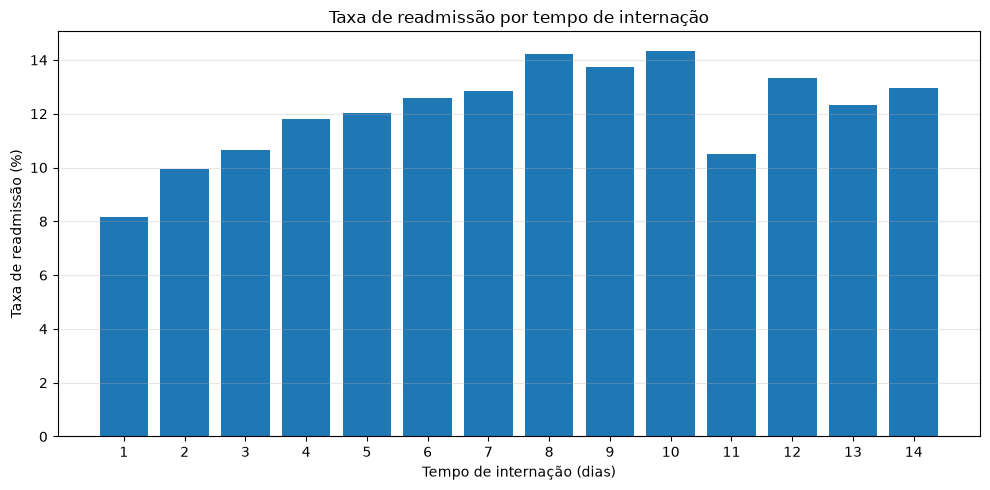

In [13]:
# 18. Taxa de readmissão de acordo com o tempo de internação

import matplotlib.pyplot as plt

# Calcular a quantidade de atendimentos e a taxa de readmissão
analise_internacao = (
    df.groupby("time_in_hospital")["readmitido_30_dias"]
    .agg(
        total_atendimentos="count",
        total_readmissoes="sum",
        taxa_readmissao="mean"
    )
)

# Converter a taxa para percentual
analise_internacao["taxa_readmissao"] *= 100

# Criar o gráfico
plt.figure(figsize=(10, 5))

plt.bar(
    analise_internacao.index,
    analise_internacao["taxa_readmissao"]
)

plt.title("Taxa de readmissão por tempo de internação")
plt.xlabel("Tempo de internação (dias)")
plt.ylabel("Taxa de readmissão (%)")
plt.xticks(analise_internacao.index)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Taxa de readmissão por quantidade de internações anteriores
Os resultados indicam uma associação positiva entre a quantidade de internações anteriores e a taxa de readmissão em até 30 dias. Os pacientes com histórico mais elevado de internações apresentam, em geral, taxas maiores de readmissão. Entretanto, os grupos com muitas internações anteriores possuem poucos registros, o que exige cautela na interpretação dos percentuais.

OBS: number_inpatient representa a quantidade de internações anteriores do paciente

,total_atendimentos,total_readmissoes,taxa_readmissao
number_inpatient,,,
0,67630,5706,8.44
1,19521,2523,12.92
2,7566,1319,17.43
3,3411,692,20.29
4,1622,383,23.61
5,812,255,31.40
6,480,166,34.58
7,268,95,35.45
8,151,67,44.37


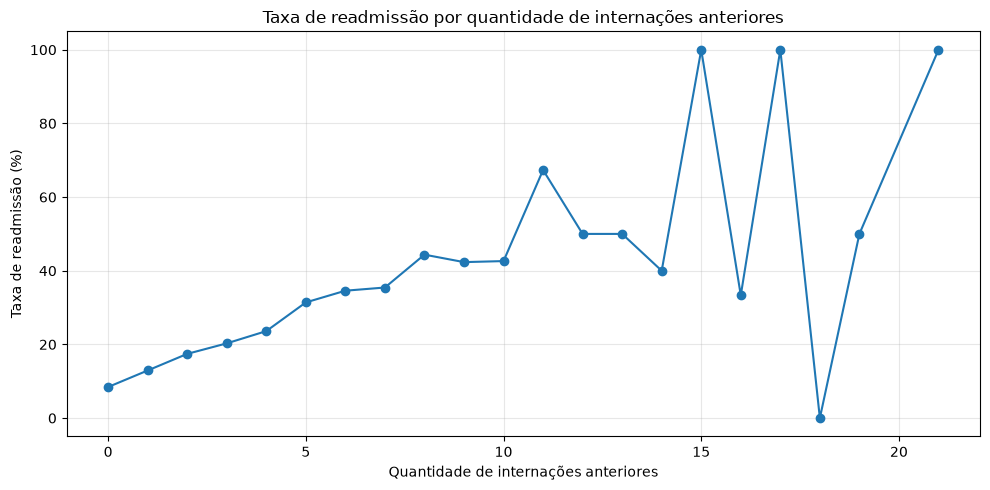

In [14]:
# 19. Taxa de readmissão de acordo com internações anteriores

# Agrupar os atendimentos pela quantidade de internações anteriores
analise_internacoes_anteriores = (
    df.groupby("number_inpatient")["readmitido_30_dias"]
    .agg(
        total_atendimentos="count",
        total_readmissoes="sum",
        taxa_readmissao="mean"
    )
)

# Converter a taxa para percentual
analise_internacoes_anteriores["taxa_readmissao"] *= 100

# Exibir a tabela de resultados
display(analise_internacoes_anteriores.round(2))

# Criar o gráfico
plt.figure(figsize=(10, 5))

plt.plot(
    analise_internacoes_anteriores.index,
    analise_internacoes_anteriores["taxa_readmissao"],
    marker="o"
)

plt.title("Taxa de readmissão por quantidade de internações anteriores")
plt.xlabel("Quantidade de internações anteriores")
plt.ylabel("Taxa de readmissão (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Taxa de readmissão por uso de insulina
- Pacientes que tiveram redução da dose de insulina apresentaram a maior taxa de readmissão: 13,90%.
- Pacientes que tiveram aumento da dose também apresentaram uma taxa relativamente elevada: 12,99%.
- Pacientes que não utilizaram insulina apresentaram a menor taxa: 10,04%.
- A manutenção da dose apresentou uma taxa intermediária: 11,13%.
Isso sugere uma associação entre alterações no uso de insulina e maiores taxas de readmissão.

,Total de atendimentos,Readmissões em até 30 dias,Taxa de readmissão (%)
insulin,,,
Down,12218,1698,13.90
No,47383,4756,10.04
Steady,30849,3433,11.13
Up,11316,1470,12.99


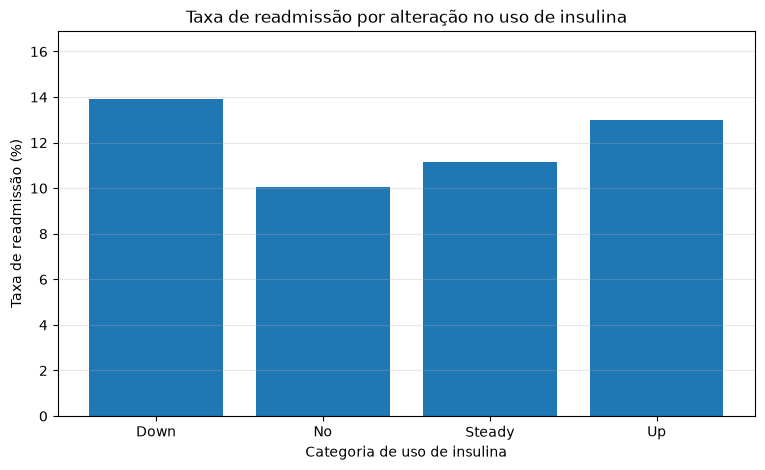

In [15]:
# 20. Taxa de readmissão por uso de insulina

analise_insulina = (
    df.groupby("insulin")["readmitido_30_dias"]
    .agg(["count", "sum", "mean"])
)

analise_insulina = analise_insulina.rename(columns={
    "count": "Total de atendimentos",
    "sum": "Readmissões em até 30 dias",
    "mean": "Taxa de readmissão (%)"
})

analise_insulina["Taxa de readmissão (%)"] *= 100

display(analise_insulina.round(2))

# Construção do gráfico
plt.figure(figsize=(9, 5))

plt.bar(
    analise_insulina.index,
    analise_insulina["Taxa de readmissão (%)"]
)

plt.title("Taxa de readmissão por alteração no uso de insulina")
plt.xlabel("Categoria de uso de insulina")
plt.ylabel("Taxa de readmissão (%)")
plt.ylim(0, analise_insulina["Taxa de readmissão (%)"].max() + 3)
plt.grid(axis="y", alpha=0.3)

plt.show()

### Taxa de readmissão por faixa etária
A análise da distribuição das readmissões por faixa etária identificou diferenças entre os grupos. A faixa de 20 a 30 anos apresentou a maior taxa de readmissão em até 30 dias, com 14,24%. Entre as faixas a partir dos 30 anos, os percentuais permaneceram relativamente próximos, variando entre 9,67% e 12,08%. Os resultados não demonstram uma relação linear entre o avanço da idade e o aumento das readmissões, indicando que outros fatores também podem estar associados ao fenômeno.

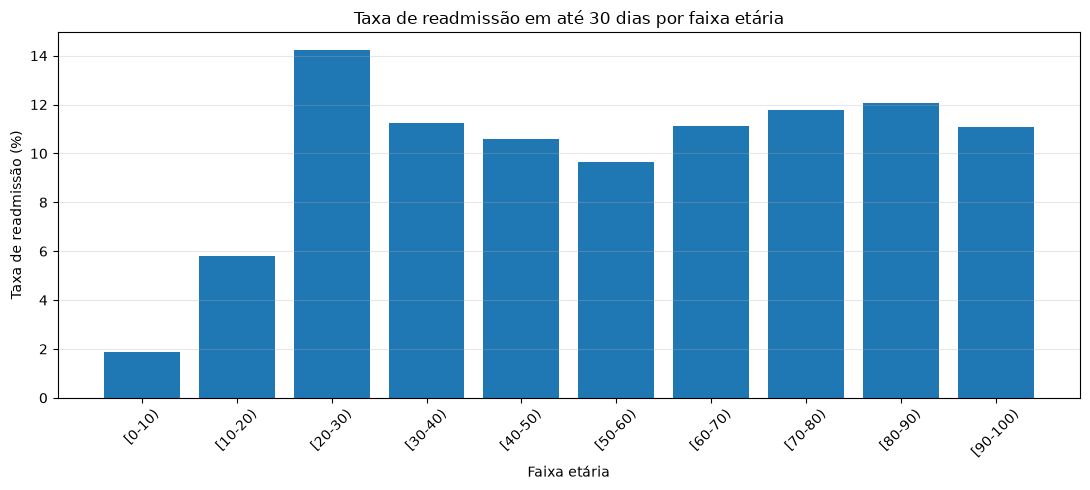

In [16]:
# 21. Taxa de readmissão por faixa etária

plt.figure(figsize=(11, 5))

plt.bar(
    analise_idade.index,
    analise_idade["Taxa de readmissão (%)"]
)

plt.title("Taxa de readmissão em até 30 dias por faixa etária")
plt.xlabel("Faixa etária")
plt.ylabel("Taxa de readmissão (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Taxa de readmissão por diagnóstico principal
A análise dos dez diagnósticos principais mais frequentes identificou diferenças nas taxas de readmissão em até 30 dias. A oclusão das artérias cerebrais apresentou a maior taxa, com 16,22%, seguida pela insuficiência cardíaca, com 14,11%. Já os sintomas respiratórios e torácicos apresentaram a menor taxa, com 7,25%. Os resultados indicam que o diagnóstico principal pode estar associado ao comportamento das readmissões, embora não permitam estabelecer uma relação causal.

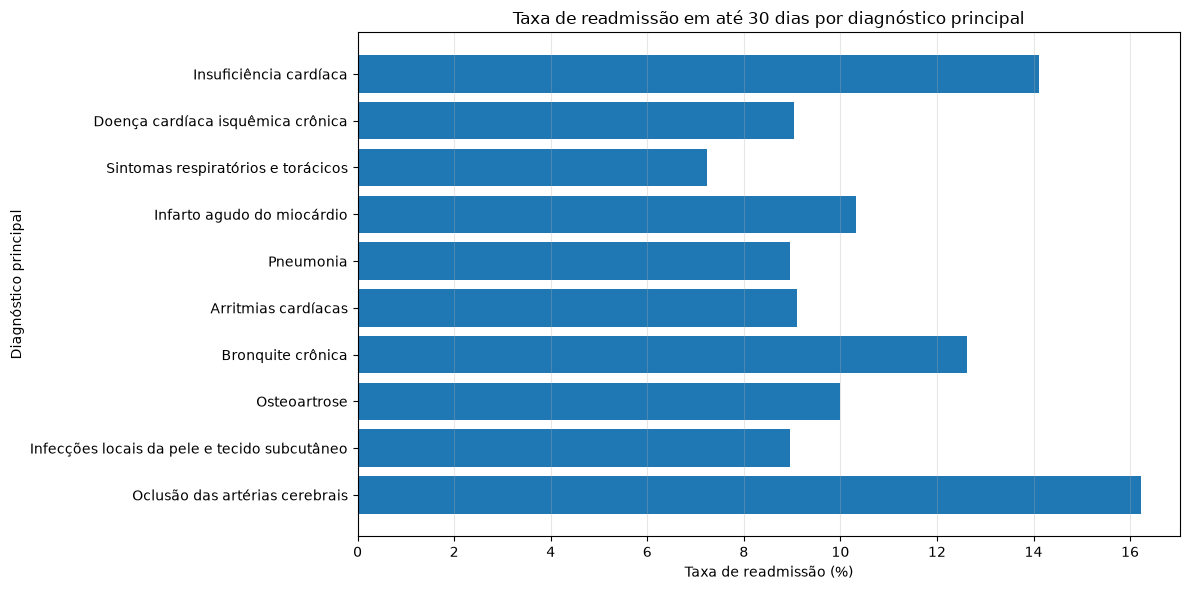

In [17]:
# 22. Taxa de readmissão por diagnóstico principal

plt.figure(figsize=(12, 6))

plt.barh(
    analise_diagnosticos["Descrição do diagnóstico"],
    analise_diagnosticos["Taxa de readmissão (%)"]
)

plt.title("Taxa de readmissão em até 30 dias por diagnóstico principal")
plt.xlabel("Taxa de readmissão (%)")
plt.ylabel("Diagnóstico principal")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## Machine Learning - Regressão Logística

In [ ]:
# Preparação das variáveis

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Seleção das variáveis numéricas (podem ser padronizadas)
variaveis_numericas = [
    "time_in_hospital",
    "number_inpatient",
    "number_emergency",
    "number_outpatient",
    "number_diagnoses"
]

# Seleção das variáveis categóricas (precisam ser transformadas em representações numericas por meio de OneHotEncoder)
variaveis_categoricas = [
    "age",
    "gender",
    "race",
    "diag_1",
    "change",
    "diabetesMed",
    "insulin"
]

# Informações que o modelo utilizará para realizar a previsão
X = df[variaveis_numericas + variaveis_categoricas].copy()

# resultado que queremos prever
y = df["readmitido_30_dias"]

print("Quantidade de registros:", len(X))
print("Quantidade de variáveis preditoras:", X.shape[1])

print("\nDistribuição da variável-alvo:")
print(y.value_counts())

Quantidade de registros: 101766
Quantidade de variáveis preditoras: 12

Distribuição da variável-alvo:
readmitido_30_dias
0    90409
1    11357
Name: count, dtype: int64


In [19]:
# 24. Configuração do pré-processamento das variáveis

# Tratamento das variáveis numéricas
transformacao_numerica = Pipeline(steps=[
    ("imputacao", SimpleImputer(strategy="median")),
    ("padronizacao", StandardScaler())
])

# Tratamento das variáveis categóricas
transformacao_categorica = Pipeline(steps=[
    ("imputacao", SimpleImputer(strategy="most_frequent")),
    ("codificacao", OneHotEncoder(handle_unknown="ignore"))
])

# Combinação dos tratamentos
preprocessador = ColumnTransformer(transformers=[
    ("numericas", transformacao_numerica, variaveis_numericas),
    ("categoricas", transformacao_categorica, variaveis_categoricas)
])

print("Pré-processamento configurado com sucesso!")

Pré-processamento configurado com sucesso!


In [ ]:
# 25. Separação dos dados em treinamento e teste

#garantimos nos dados de treino e teste tenham a mesma proporção de classes da variável-alvo para que o modelo não tenha pre-disposição para uma das classes, o que poderia prejudicar a performance do modelo. Para isso, utilizamos o parâmetro stratify=y no train_test_split.
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20, #20% dos dados serão utilizados para teste
    random_state=42,
    stratify=y
)

print("Quantidade de registros para treinamento:", len(X_treino))
print("Quantidade de registros para teste:", len(X_teste))

print("\nDistribuição das classes no treinamento:")
print(y_treino.value_counts(normalize=True) * 100)

print("\nDistribuição das classes no teste:")
print(y_teste.value_counts(normalize=True) * 100)

Quantidade de registros para treinamento: 81412
Quantidade de registros para teste: 20354

Distribuição das classes no treinamento:
readmitido_30_dias
0    88.839483
1    11.160517
Name: proportion, dtype: float64

Distribuição das classes no teste:
readmitido_30_dias
0    88.842488
1    11.157512
Name: proportion, dtype: float64


In [ ]:
# 26. Construção e treinamento do modelo de Regressão Logística

# Criação do pipeline completo
modelo = Pipeline(steps=[
    ("preprocessamento", preprocessador),
    ("classificador", LogisticRegression(
        max_iter=1000,
        class_weight="balanced", #atribui pesos inversamente proporcionais à frequência das classes, dando foco no 1 (readmissão em até 30 dias)
        random_state=42
    ))
])

# Treinamento do modelo
modelo.fit(X_treino, y_treino)

print("Modelo de Regressão Logística treinado com sucesso!")

Modelo de Regressão Logística treinado com sucesso!


In [22]:
# 27. Realização das previsões com o modelo treinado

# Previsão das classes
previsoes = modelo.predict(X_teste)

# Probabilidade estimada de readmissão
probabilidades = modelo.predict_proba(X_teste)[:, 1]

print("Previsões realizadas com sucesso!")

print("\nPrimeiras 10 previsões:")
print(previsoes[:10])

print("\nPrimeiras 10 classes reais:")
print(y_teste.iloc[:10].values)

print("\nProbabilidades de readmissão:")
print(probabilidades[:10].round(3))

Previsões realizadas com sucesso!

Primeiras 10 previsões:
[1 0 0 1 0 0 0 0 1 1]

Primeiras 10 classes reais:
[0 0 0 1 1 0 0 0 0 0]

Probabilidades de readmissão:
[0.58  0.358 0.489 0.574 0.377 0.396 0.367 0.381 0.65  0.622]


In [23]:
# 28. Avaliação do desempenho do modelo

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Calcular métricas de avaliação
acuracia = accuracy_score(y_teste, previsoes)
precisao = precision_score(y_teste, previsoes, zero_division=0)
revocacao = recall_score(y_teste, previsoes, zero_division=0)
f1 = f1_score(y_teste, previsoes, zero_division=0)

# Exibir resultados
print("MÉTRICAS DE AVALIAÇÃO DO MODELO")
print("-" * 40)

print(f"Acurácia:  {acuracia:.4f} ({acuracia * 100:.2f}%)")
print(f"Precisão:  {precisao:.4f} ({precisao * 100:.2f}%)")
print(f"Revocação: {revocacao:.4f} ({revocacao * 100:.2f}%)")
print(f"F1-score:  {f1:.4f}")

print("\nRelatório de classificação:")
print(classification_report(
    y_teste,
    previsoes,
    target_names=["Sem readmissão", "Com readmissão"],
    zero_division=0
))

MÉTRICAS DE AVALIAÇÃO DO MODELO
----------------------------------------
Acurácia:  0.6497 (64.97%)
Precisão:  0.1675 (16.75%)
Revocação: 0.5390 (53.90%)
F1-score:  0.2556

Relatório de classificação:
                precision    recall  f1-score   support

Sem readmissão       0.92      0.66      0.77     18083
Com readmissão       0.17      0.54      0.26      2271

      accuracy                           0.65     20354
     macro avg       0.54      0.60      0.51     20354
  weighted avg       0.84      0.65      0.71     20354



Matriz de confusão:
[[12001  6082]
 [ 1047  1224]]


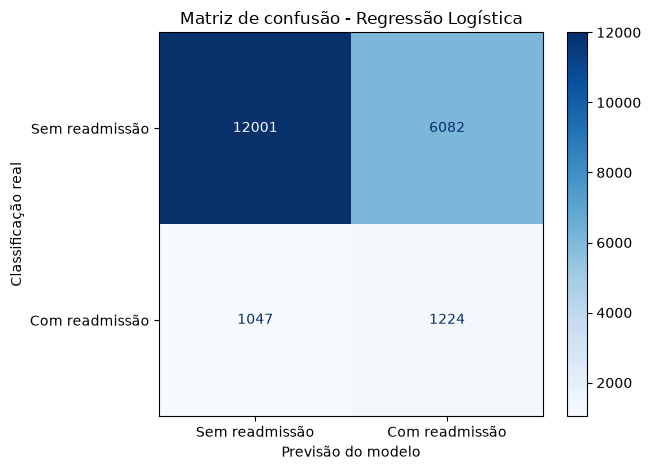

In [24]:
# 29. Matriz de confusão

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calcular a matriz de confusão
matriz = confusion_matrix(y_teste, previsoes)

# Exibir os valores
print("Matriz de confusão:")
print(matriz)

# Criar visualização
visualizacao = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Sem readmissão", "Com readmissão"]
)

visualizacao.plot(cmap="Blues", values_format="d")

plt.title("Matriz de confusão - Regressão Logística")
plt.xlabel("Previsão do modelo")
plt.ylabel("Classificação real")
plt.tight_layout()
plt.show()

In [29]:
# 30. Preparação das variáveis categóricas para o modelo balanceado

# Criar cópias dos conjuntos de treinamento e teste
X_treino_balanceado = X_treino.copy()
X_teste_balanceado = X_teste.copy()

# Transformar variáveis categóricas em colunas numéricas
X_treino_balanceado = pd.get_dummies(
    X_treino_balanceado,
    dtype=int
)

X_teste_balanceado = pd.get_dummies(
    X_teste_balanceado,
    dtype=int
)

# Garantir que treinamento e teste tenham as mesmas colunas
X_teste_balanceado = X_teste_balanceado.reindex(
    columns=X_treino_balanceado.columns,
    fill_value=0
)

print("Preparação das variáveis concluída!")
print("Variáveis após transformação:", X_treino_balanceado.shape[1])
print("Valores ausentes no treinamento:", X_treino_balanceado.isnull().sum().sum())
print("Valores ausentes no teste:", X_teste_balanceado.isnull().sum().sum())

Preparação das variáveis concluída!
Variáveis após transformação: 726
Valores ausentes no treinamento: 0
Valores ausentes no teste: 0


In [30]:
# 31. Treinamento do modelo com balanceamento de classes

modelo_balanceado = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

modelo_balanceado.fit(
    X_treino_balanceado,
    y_treino
)

# Realizar previsões
previsoes_balanceadas = modelo_balanceado.predict(
    X_teste_balanceado
)

print("Modelo com balanceamento treinado com sucesso!")

Modelo com balanceamento treinado com sucesso!


In [31]:
# 32. Avaliação do modelo com balanceamento de classes

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calcular métricas
acuracia_balanceada = accuracy_score(y_teste, previsoes_balanceadas)
precisao_balanceada = precision_score(y_teste, previsoes_balanceadas)
revocacao_balanceada = recall_score(y_teste, previsoes_balanceadas)
f1_balanceado = f1_score(y_teste, previsoes_balanceadas)

# Exibir resultados
print("MÉTRICAS DO MODELO COM BALANCEAMENTO")
print("----------------------------------------")
print(f"Acurácia:  {acuracia_balanceada:.4f} ({acuracia_balanceada:.2%})")
print(f"Precisão:  {precisao_balanceada:.4f} ({precisao_balanceada:.2%})")
print(f"Revocação: {revocacao_balanceada:.4f} ({revocacao_balanceada:.2%})")
print(f"F1-score:  {f1_balanceado:.4f}")

print("\nRelatório de classificação:")
print(classification_report(
    y_teste,
    previsoes_balanceadas,
    target_names=["Sem readmissão", "Com readmissão"]
))

MÉTRICAS DO MODELO COM BALANCEAMENTO
----------------------------------------
Acurácia:  0.6501 (65.01%)
Precisão:  0.1683 (16.83%)
Revocação: 0.5421 (54.21%)
F1-score:  0.2569

Relatório de classificação:
                precision    recall  f1-score   support

Sem readmissão       0.92      0.66      0.77     18083
Com readmissão       0.17      0.54      0.26      2271

      accuracy                           0.65     20354
     macro avg       0.54      0.60      0.51     20354
  weighted avg       0.84      0.65      0.71     20354



Matriz de confusão do modelo balanceado:
[[12001  6082]
 [ 1040  1231]]


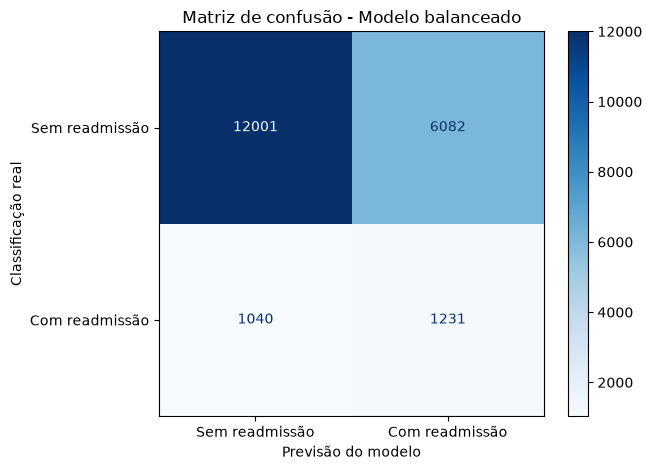

In [32]:
# 33. Matriz de confusão do modelo balanceado

matriz_balanceada = confusion_matrix(
    y_teste,
    previsoes_balanceadas
)

print("Matriz de confusão do modelo balanceado:")
print(matriz_balanceada)

visualizacao_balanceada = ConfusionMatrixDisplay(
    confusion_matrix=matriz_balanceada,
    display_labels=["Sem readmissão", "Com readmissão"]
)

visualizacao_balanceada.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de confusão - Modelo balanceado")
plt.xlabel("Previsão do modelo")
plt.ylabel("Classificação real")
plt.tight_layout()
plt.show()

## 34. Análise das limitações do modelo

Durante o desenvolvimento do modelo de Regressão Logística, identificamos uma limitação importante relacionada ao desequilíbrio das classes da variável-alvo `readmitido_30_dias`.

Na distribuição original dos dados, aproximadamente 88,84% dos atendimentos não resultaram em readmissão em até 30 dias, enquanto apenas 11,16% apresentaram readmissão. Essa diferença representa um desafio para o treinamento de modelos de classificação, pois a classe minoritária possui uma quantidade significativamente menor de registros.

### Comparação entre os modelos

Foram avaliadas duas configurações de Regressão Logística:

- **Modelo original:** treinado sem ajuste de pesos entre as classes.
- **Modelo balanceado:** treinado utilizando o parâmetro `class_weight="balanced"`, que atribui pesos maiores à classe minoritária durante o treinamento.

Os resultados demonstraram uma melhora discreta após o balanceamento:

| Métrica | Modelo original | Modelo balanceado |
|---|---:|---:|
| Acurácia | 64,97% | 65,01% |
| Precisão | 16,75% | 16,83% |
| Revocação | 53,90% | 54,21% |
| F1-score | 0,2556 | 0,2569 |

### Interpretação dos resultados

Apesar da pequena melhora, o modelo ainda apresenta limitações importantes:

- A precisão de aproximadamente 17% indica que uma parcela significativa das previsões de readmissão está incorreta.
- A revocação de aproximadamente 54% demonstra que o modelo identifica pouco mais da metade dos casos reais de readmissão.
- A quantidade elevada de falsos positivos indica dificuldade em distinguir os atendimentos que realmente resultarão em readmissão daqueles que não resultarão.

O balanceamento por pesos contribuiu para uma pequena melhora na identificação da classe minoritária, mas não foi suficiente para resolver as dificuldades relacionadas à distribuição dos dados.

### Conclusão

Os resultados mostram que o desequilíbrio da variável-alvo representa um desafio relevante para a capacidade preditiva do modelo. Além disso, a utilização de uma única abordagem de classificação limita a avaliação de outras possibilidades metodológicas.

Dessa forma, consideramos que o modelo desenvolvido atende ao objetivo de demonstrar a aplicação de técnicas de classificação aos dados, mas seus resultados ainda não são suficientemente consistentes para uma utilização prática sem aprimoramentos e validações adicionais.

Essa limitação deve ser considerada em etapas futuras do projeto, nas quais poderão ser investigadas outras estratégias de tratamento do desequilíbrio e diferentes algoritmos de classificação.

# 35. Conclusão geral

Este projeto teve como objetivo investigar quais fatores estão associados às readmissões hospitalares em até 30 dias após a alta de pacientes com diabetes, utilizando o conjunto de dados *Diabetes 130-US Hospitals for Years 1999–2008*, composto originalmente por 101.766 atendimentos registrados em 130 hospitais dos Estados Unidos.

Durante o desenvolvimento, realizamos a ingestão, inspeção, limpeza e preparação dos dados, identificando valores ausentes, avaliando a existência de registros duplicados e adequando variáveis para as etapas de análise e modelagem.

A análise exploratória permitiu identificar diferenças nas taxas de readmissão entre grupos de pacientes e características dos atendimentos. Entre os resultados observados, destacam-se:

- As taxas de readmissão variaram entre as diferentes faixas etárias, com destaque para a faixa de 20 a 30 anos, que apresentou uma taxa de aproximadamente 14,24%.
- Atendimentos com maior quantidade de internações anteriores apresentaram, em geral, taxas mais elevadas de readmissão. Entretanto, as categorias com muitas internações possuem poucos registros, exigindo cautela na interpretação.
- As categorias relacionadas ao uso de insulina também apresentaram diferenças nas taxas de readmissão. A categoria `Down` apresentou aproximadamente 13,90%, enquanto a categoria `No` apresentou 10,04%.
- Os diagnósticos principais também demonstraram variações nas taxas de readmissão, indicando que diferentes condições clínicas podem estar associadas a diferentes padrões de retorno hospitalar.

Na etapa de modelagem, desenvolvemos um modelo de Regressão Logística para classificar os atendimentos quanto à ocorrência de readmissão em até 30 dias. O modelo original apresentou acurácia de 64,97%, precisão de 16,75% e revocação de 53,90%.

Posteriormente, aplicamos o balanceamento de classes por meio do parâmetro `class_weight="balanced"`. Apesar de apresentar uma pequena melhora, com acurácia de 65,01%, precisão de 16,83% e revocação de 54,21%, o modelo continuou apresentando limitações na identificação dos casos de readmissão.

Um dos principais desafios encontrados foi o desequilíbrio da variável-alvo: aproximadamente 88,84% dos atendimentos não tiveram readmissão em até 30 dias, enquanto apenas 11,16% apresentaram esse resultado. Essa característica influenciou o desempenho do classificador e demonstrou a importância de considerar a distribuição das classes durante a avaliação de modelos preditivos.

De maneira geral, o projeto permitiu compreender melhor a estrutura dos dados, identificar características associadas às readmissões hospitalares e aplicar técnicas de análise e aprendizado de máquina. Também evidenciou que a identificação de padrões não significa necessariamente estabelecer relações de causa e efeito.

Concluímos que os resultados obtidos representam uma etapa inicial de investigação e que o modelo desenvolvido ainda não apresenta desempenho suficiente para uma aplicação prática sem novas avaliações. Como possibilidades de continuidade, destacam-se a investigação de outros algoritmos, estratégias de tratamento do desbalanceamento e técnicas adicionais de seleção e preparação de variáveis.

Assim, o projeto estabelece uma base para etapas futuras de análise, contribuindo para a compreensão dos fatores relacionados às readmissões hospitalares de pacientes com diabetes.